# Explore
Explore what subreddits relate to or mention resumes.

In [3]:
from dotenv import load_dotenv
import os

In [4]:
load_dotenv()

True

In [5]:
client_id = os.environ.get("REDDIT_CLIENT_ID")
client_secret = os.environ.get("REDDIT_CLIENT_SECRET")

In [6]:
import praw

client= praw.Reddit(
    client_id=client_id,
    client_secret=client_secret,
    user_agent="research/0.1"
)

## Exploring Subreddits
Found that r/resumes is a prominent subreddit

In [7]:
resume_subs = client.subreddits.search_by_name("resume")

for sub in resume_subs:
    print(f"r/{sub.display_name} - {sub.subscribers:,} subscribers")

r/Resume - 130,909 subscribers
r/resumes - 1,328,690 subscribers
r/ResumeExperts - 29,637 subscribers
r/ResumeTips - 18,217 subscribers
r/ResumeCoverLetterTips - 27,872 subscribers
r/resumesupport - 8,780 subscribers
r/resumesindia - 7,393 subscribers
r/resumeph - 16 subscribers
r/ResumeFairies - 7,083 subscribers
r/resumereview - 2,295 subscribers


## Downloading sample of r/resumes Posts
Retrieved all posts with >=1 comment over time period spanning January 1st, 2026 to November 1st, 2026.

In [8]:
import deepsift

In [9]:
from deepsift.scraper import RedditScraper
from deepsift.filters import Filters
from deepsift.models import PostField

filters = Filters(
    post_include_fields=[
        PostField.ID,
        PostField.TITLE,
        PostField.SELFTEXT,
        PostField.SCORE,
        PostField.NUM_COMMENTS,
        PostField.CREATED_UTC,
        PostField.SUBREDDIT,
        PostField.URL
    ],
    post_filter=lambda post: post.num_comments >= 1,
)

scraper = RedditScraper(
    filters=filters,
    post_workers=4,
    shard_days=30,
)

# uncomment to run extraction
# post_ids = scraper.scrape_posts(
#     subreddits=["resumes"],
#     from_dt="2026-01-01",
#     to_dt="2026-11-01",
#     output_path="data/subreddit_resumes_posts.parquet",
# )

# print(f"Scraped {len(post_ids)} curated posts.")

## Finding Relevant Posts in Retrieved Data

In [10]:
import pandas as pd

posts_path = "data/subreddit_resumes_posts.parquet"
posts = pd.read_parquet(posts_path)

In [11]:
posts.shape

(20827, 8)

In [12]:
# validating the time period was respected
posts["created_utc"] = pd.to_datetime(posts["created_utc"], unit="s")

In [13]:
# this validates that it we did get data for the complete time period requested
posts["created_utc"].describe()

count                         20827
mean     2026-05-14 14:14:26.002256
min             2026-01-01 00:29:21
25%      2026-02-25 15:13:13.500000
50%             2026-05-04 21:39:57
75%             2026-07-28 12:10:49
max             2026-10-31 22:55:34
Name: created_utc, dtype: object

In [14]:
# remove posts with empty selftext, as they are likely to be irrelevant posts
is_nonempty_text = posts["selftext"].str.strip().str.len() > 1
not_empty_posts = posts[is_nonempty_text]
not_empty_posts["selftext"].str.len().describe()

count    18801.000000
mean       345.065156
std        548.040952
min          4.000000
25%          9.000000
50%         54.000000
75%        519.000000
max      11280.000000
Name: selftext, dtype: float64

In [15]:
# checks posts with text less than 25% of the full dataset, as they may be irrelevant posts (found '[removed]' posts and '[deleted]' posts)
is_sufficient_length = not_empty_posts["selftext"].str.len() < not_empty_posts["selftext"].str.len().quantile(0.5)
is_valid_text = posts["selftext"].str.lower().isin(["[removed]", "[deleted]"]) == False
pd.DataFrame(not_empty_posts[is_sufficient_length]["selftext"].value_counts()).head(5)

,count
selftext,
[removed],9071
[deleted],79
Any feedback is appreciated!,3
Roast my resume,3
Looking for feedback on my resume,2


In [16]:
# filter out the rows to only valid posts with sufficient text length
sufficient_text_posts = posts[is_valid_text & is_nonempty_text]
sufficient_text_posts.shape

(9651, 8)

In [17]:
# filter out the duplicates
no_dups_sufficient_text_posts = sufficient_text_posts.drop_duplicates(subset=["selftext"])
no_dups_sufficient_text_posts.shape

(9501, 8)

In [18]:
# check url file types to see if there are any image attachments
endings = pd.DataFrame(no_dups_sufficient_text_posts["url"].str.split(".").str[-1].str.lower().value_counts())
likely_extensions = endings[endings.index.str.len() < 10]
likely_extensions.head(5)

,count
url,
jpeg,2108
png,1676
0,1
cv,1
pro/,1


In [19]:
# only keep posts with image attachments
has_attachment = no_dups_sufficient_text_posts["url"].str.split(".").str[-1].str.lower().isin(["jpeg", "png"])
valid_posts_w_attachments = no_dups_sufficient_text_posts[has_attachment]
valid_posts_w_attachments.shape

(3784, 8)

In [20]:
# only keep posts with a resume type in the title, which is usually in the format of [resume type]
pattern = r"\[(.*)\]"
valid_posts_w_attachments["resume_type"] = valid_posts_w_attachments["title"].str.extract(pattern)
valid_posts_w_attachments.shape

(3784, 9)

In [ ]:
# actually parse the resume type from the title using regex
import re
import matplotlib.pyplot as plt

def extract_number(phrase) -> int | None:
    # if number exists in the phrase it returns it else None

    number_exists_pattern = ".*([0-9]+).*"
    number = re.search(number_exists_pattern, phrase)
    if number:
        return int(number.group(1))

    return None

def parse_exp_years(phrase) -> int | None:

    if "yoe" in phrase.lower() and len(phrase.strip().split()) <= 2:
        return extract_number(phrase)
    elif "years" in phrase.lower() and len(phrase.strip().split()) <= 2:
        return extract_number(phrase)
    elif "months" in phrase.lower() and len(phrase.strip().split()) <= 3:
        return extract_number(phrase) / 12 # divide by 12 to return year

    return None

def parse_country(phrase) -> str | None:
    # parses country if it exists in the phrase, else it returns None

def parse_resume_type(row):

    pattern = r"\[(.*)\]"
    match = re.search(pattern, row["title"])

    res: dict = {}

    if match:
        statement = match.group(1)

        # [X YoE, Current Role/Unemployed, Target Role, Country]
        res["relevant_part"] = statement

        # filter so only 4 parts exist
        parts = statement.split(",")
        if len(parts) != 4:
            return res

        # get years of experience
        years_exp = parse_exp_years(parts[0])
        if years_exp is not None:
            res["years_exp"] = years_exp

        # get current role
        current_role = parts[1]
        if current_role is not None:
            res["current_role"] = current_role

        # get target role
        target_role = parts[2]
        if target_role is not None:
            res["target_role"] = target_role

        # get country
        country = parts[3]
        if country is not None:
            res["country"] = country

    return res

results = valid_posts_w_attachments.apply(parse_resume_type, axis=1, result_type="expand")
extracted = valid_posts_w_attachments.join(results)

In [38]:
country_len = extracted["country"].str.len()
lower, upper = country_len.quantile(0.25), country_len.quantile(0.75)
iqr = upper - lower
lower_bound, upper_bound = lower - 1.5 * iqr, upper + 1.5 * iqr

In [41]:
country_len.describe()

count    3528.000000
mean        8.942744
std         5.252578
min         1.000000
25%         4.000000
50%         7.000000
75%        14.000000
max        58.000000
Name: country, dtype: float64

In [39]:
lower_bound

np.float64(-11.0)

In [40]:
upper_bound

np.float64(29.0)

In [33]:
# format of the relevant part: https://www.reddit.com/r/resumes/wiki/index/howtoparticipate/?screen_view_count=1
extracted[["relevant_part", "years_exp", "current_role", "target_role", "country", "url"]]

,relevant_part,years_exp,current_role,target_role,country,url
3,"4 YoE, Sub Teacher, Remote/USA, Looking to Piv...",4.0,Sub Teacher,Remote/USA,Looking to Pivot into Customer Service/IT Jobs,https://i.redd.it/5q7fhepjnzmh1.png
4,"3 YoE, Art Director/Laid Off, 2D artist/concep...",3.0,Art Director/Laid Off,2D artist/concept artist,Remote/USA,https://i.redd.it/83sxfzzyjzmh1.png
7,"5 YoE, Cyber Security Engineer, Cyber Security...",5.0,Cyber Security Engineer,Cyber Security Professional,United States,https://i.redd.it/nbf46vpagzmh1.png
14,"3 YoE, Enterprise Technology Consultant, Techn...",3.0,Enterprise Technology Consultant,Technology Transformation Consultant,United States,https://i.redd.it/l520cpuicymh1.jpeg
16,"11 YoE, Customer Service Rep, Content Moderati...",1.0,Customer Service Rep,Content Moderation,USA,https://i.redd.it/iwq1hj0d5ymh1.png
...,...,...,...,...,...,...
20802,"1st Year University Student, intern, Business ...",NaN,intern,Business Field,United State,https://i.redd.it/zuz583is9hbg1.jpeg
20804,"0 YOE, Data Analyst Co-op, Data Science Co-op,...",0.0,Data Analyst Co-op,Data Science Co-op,Canada,https://i.redd.it/7j0oeidtvgbg1.png
20809,"3 years, intern, intern, USA",3.0,intern,intern,USA,https://i.redd.it/uiworsxzkgbg1.jpeg
20817,"7 YOE, Employed, System Administrator/Cloud Ad...",7.0,Employed,System Administrator/Cloud Administrator,USA,https://i.redd.it/uzffeoknwfbg1.png


<Axes: ylabel='Frequency'>

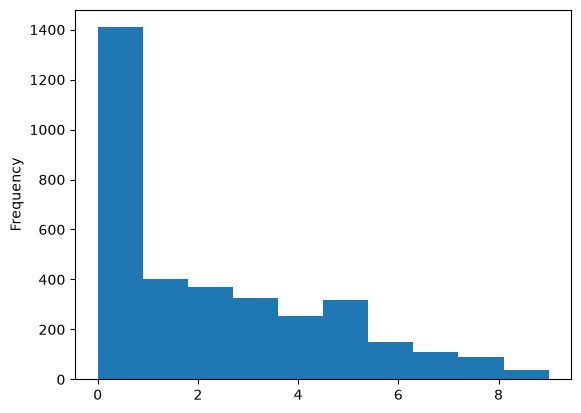

In [22]:
results["years_exp"].plot.hist()